# Calibration Study - VT-fixed COLMAP

Same pipeline as calib_raw, but with poses solved by COLMAP with the VT intrinsics held fixed (KBCB_colm_vt)

In [1]:
# IMPORTS

from gnav_calib import gNAV_calib

import numpy as np
import open3d as o3d
import cv2
import matplotlib.pyplot as plt


# SAVE YOUR WORK
%load_ext autoreload
%autoreload 2
%autosave 180

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


Autosaving every 180 seconds


In [2]:
# Upload dataset inputs

# Colmap data (VT intrinsics fixed during mapping)
colm_fn = "../datasets/KBCB_colm_vt/"

# Local test images 
im_local = '../datasets/KBCB_test_images_raw/' # With 10 local images 

# Satellite ref 
sat_ref = "../datasets/KBCB_satellite/KBCB_partial.jpg" # Public google earth satellite imagery

# Ground truth solutions
ind_params_KBCB = np.load("ind_params_KBCB_FULL.npy") # NEED NEW********

In [3]:
# K and distortion params
# VT intrinsics (ROS yaml): rational_polynomial = [k1 k2 p1 p2 k3 k4 k5 k6]
# Same values as FULL_OPENCV in KBCB_colm_vt/cameras.txt (held fixed in the COLMAP run)
import yaml
with open('../datasets/KBCB_config/camera_forward.yaml') as fh:
    vt = yaml.safe_load(fh)
K = np.array(vt['camera_matrix']['data']).reshape(3,3)
dist = np.array(vt['distortion_coefficients']['data'])
print(K); print(dist)

[[1.61482951e+03 0.00000000e+00 1.23500441e+03]
 [0.00000000e+00 1.61997672e+03 6.96002777e+02]
 [0.00000000e+00 0.00000000e+00 1.00000000e+00]]
[ 4.90967308e+01  8.42090797e+01  5.78514307e-05 -1.67231838e-04
  2.52012578e+01  4.93039768e+01  9.57972418e+01  3.89384233e+01]


In [4]:
# Create class 
gnav = gNAV_calib(colm_fn, im_local, sat_ref, ind_params_KBCB, K, dist)

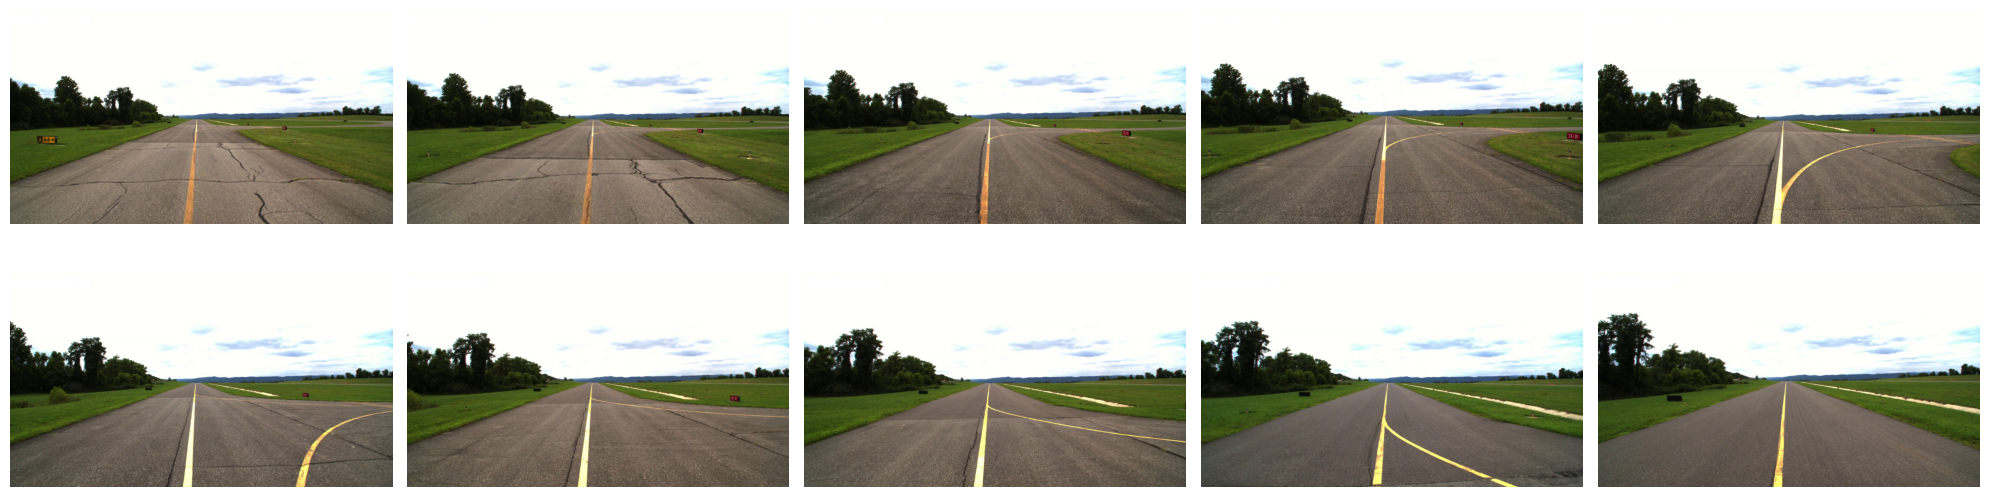

In [5]:
# Visualizer 
gnav.visualize_local_ims()

In [6]:
# Visualize full VT cloud (COLMAP colors) + 10 test camera centers (red)
vis = o3d.visualization.Visualizer()
vis.create_window(window_name='VT cloud + test cams')

cloud = o3d.geometry.PointCloud()
cloud.points = o3d.utility.Vector3dVector(gnav.scene_pts)
cloud.colors = o3d.utility.Vector3dVector(gnav.scene_rgb)
vis.add_geometry(cloud)

# Test camera centers as red spheres (radius 0.05 COLMAP units - hardcoded for VT scale, ~5x smaller than April)
for i in gnav.im_ids:
    s = o3d.geometry.TriangleMesh.create_sphere(radius=0.05)
    s.translate(gnav.images_c[i].projection_center())
    s.paint_uniform_color([1.0, 0, 0])
    vis.add_geometry(s)

vis.add_geometry(o3d.geometry.TriangleMesh.create_coordinate_frame(size=1))
vis.run()
vis.destroy_window()

In [7]:
# Keep only points near the 10 test cameras (R in COLMAP units - tune by eye)
# VT recon ~5x smaller than April (cam path 12.5 vs 62.7) -> R_keep 2 (April 10), RANSAC thresh 0.0002 (April 0.001)
R_keep = 2.0
C = np.array([gnav.images_c[i].projection_center() for i in gnav.im_ids])
d = np.min(np.linalg.norm(gnav.scene_pts[:, None] - C[None], axis=2), axis=1)
near_idx = np.where(d < R_keep)[0]

# # RANSAC plane on the trimmed cloud, then map back to full scene_pts indices
# pcd = o3d.geometry.PointCloud(o3d.utility.Vector3dVector(gnav.scene_pts[near_idx]))
# plane, inl = pcd.segment_plane(distance_threshold=0.0002, ransac_n=3, num_iterations=1000)
# pts_gnd_idx = near_idx[inl]
# print(len(near_idx), 'near pts,', len(pts_gnd_idx), 'ground pts')   # 12895 near, 1165 ground

# # Downsample ground pts (grav_SVD builds an N x N matrix - keep ~2000)
# np.random.seed(17)
# pts_gnd_idx = np.random.choice(pts_gnd_idx, min(2000, len(pts_gnd_idx)), replace=False)

# Pre-calculated VT ground pts (1165, RANSAC above - saved once, RANSAC is random)
pts_gnd_idx = np.load('../datasets/KBCB_params/ground_pts_idxs_vt.npy')
gnav.pts_gnd_idx = pts_gnd_idx

In [8]:
# Visualize trimmed cloud (near_idx) with ground points in red
vis = o3d.visualization.Visualizer()
vis.create_window(window_name='Trimmed cloud + GROUND pts')

# Near-camera cloud in its COLMAP colors
near_cloud = o3d.geometry.PointCloud()
near_cloud.points = o3d.utility.Vector3dVector(gnav.scene_pts[near_idx])
near_cloud.colors = o3d.utility.Vector3dVector(gnav.scene_rgb[near_idx])

# Ground points in red
gnd_cloud = o3d.geometry.PointCloud()
gnd_cloud.points = o3d.utility.Vector3dVector(gnav.scene_pts[pts_gnd_idx])
gnd_cloud.paint_uniform_color([1.0, 0, 0])

vis.add_geometry(o3d.geometry.TriangleMesh.create_coordinate_frame(size=1))
vis.add_geometry(near_cloud)
vis.add_geometry(gnd_cloud)
vis.run()
vis.destroy_window()

In [9]:
# Gather reference frame
tform_ref_frame = gnav.set_ref_frame() 
tform_ref_frame_pts = gnav.inv_homog_transform(tform_ref_frame)
gnav.tform_ref_frame_pts = tform_ref_frame_pts
print("\nReference frame transformation\n", tform_ref_frame_pts)

# Transform all points to the new coordinate system - for visual check 
tform_ref_frame_inv = gnav.inv_homog_transform(tform_ref_frame)
origin_ref, scene_pts_ref, scene_vec_ref = gnav.unit_vec_tform(gnav.scene_pts, gnav.origin_w, tform_ref_frame_inv)
gnav.scene_pts_ref = scene_pts_ref

Gravity vector 
 [-0.00416621  0.99997739  0.00527785]

Height h_0 =  0.12092226477275607

Reference frame transformation
 [[ 0.93296046  0.00198707  0.35997338 -0.96612186]
 [ 0.35995476  0.00642375 -0.93294765  1.38264939]
 [-0.00416621  0.99997739  0.00527785  0.87916458]
 [ 0.          0.          0.          1.        ]]


In [10]:
# Height of each test camera above the ground plane (COLMAP units)
# April: ~0.103 for all 10 -> VT expected ~0.02 (recon ~5x smaller); check consistency, not value
C = np.array([gnav.images_c[i].projection_center() for i in gnav.im_ids])
print((gnav.pts_gnd.mean(0) - C) @ gnav.grav_vec)

[0.11983504 0.12002607 0.11968096 0.11959105 0.12007809 0.12059126
 0.11998142 0.12046778 0.12066414 0.11842722]


In [11]:
# Trimmed cloud + ground pts (red) + gravity vector (green) from ground centroid
vis = o3d.visualization.Visualizer()
vis.create_window(window_name='Trimmed cloud + GROUND pts + GRAVITY')

near_cloud = o3d.geometry.PointCloud()
near_cloud.points = o3d.utility.Vector3dVector(gnav.scene_pts[near_idx])
near_cloud.colors = o3d.utility.Vector3dVector(gnav.scene_rgb[near_idx])

gnd_cloud = o3d.geometry.PointCloud()
gnd_cloud.points = o3d.utility.Vector3dVector(gnav.pts_gnd)
gnd_cloud.paint_uniform_color([1.0, 0, 0])

# Gravity arrow (length 2 COLMAP units - hardcoded for April scale)
start = gnav.pts_gnd.mean(0)
grav_line = o3d.geometry.LineSet()
grav_line.points = o3d.utility.Vector3dVector([start, start + 2.0 * gnav.grav_vec])
grav_line.lines = o3d.utility.Vector2iVector([[0, 1]])
grav_line.colors = o3d.utility.Vector3dVector([[0, 1, 0]])

vis.add_geometry(near_cloud)
vis.add_geometry(gnd_cloud)
vis.add_geometry(grav_line)
vis.run()
vis.destroy_window()


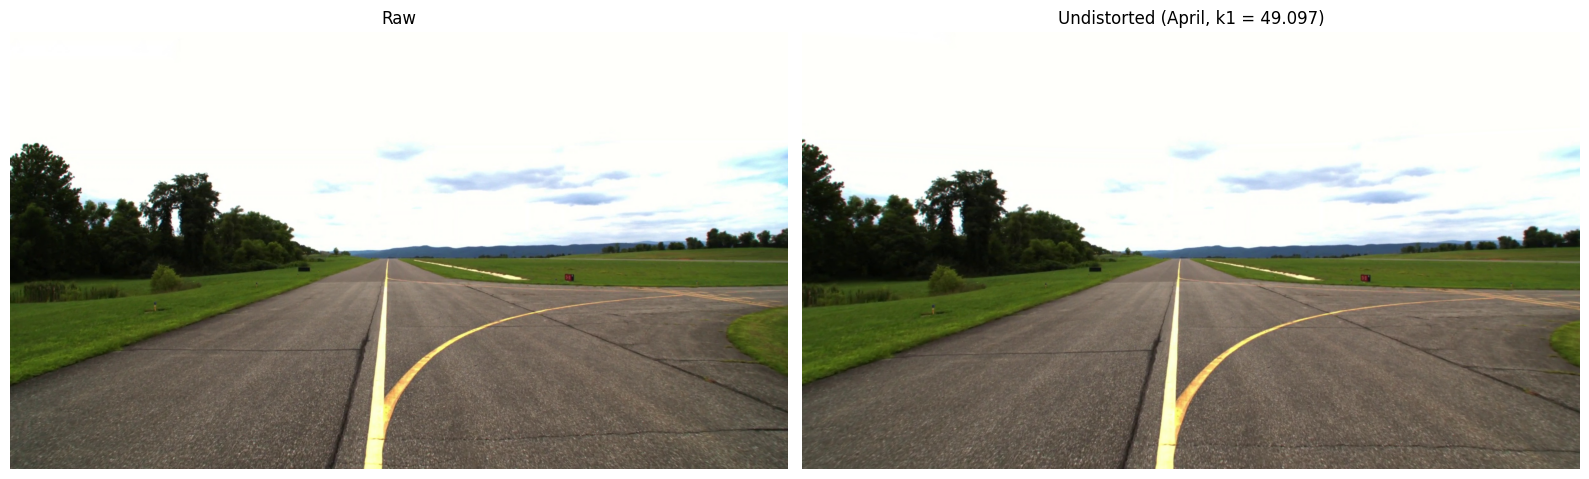

In [12]:
# Side by side: raw vs undistorted (April K, dist) - visualization only
# cv2.undistort resamples the whole image; unit_vec_c only corrects pixel coords (no resampling)
im_ind = 4
raw = gnav.images_dict[im_ind]
und = cv2.undistort(raw, gnav.K, gnav.dist)   # same K out -> same size, corners pushed off-frame

fig, axs = plt.subplots(1, 2, figsize=(16, 5))
for ax, im, name in zip(axs, [raw, und], ['Raw', f'Undistorted (April, k1 = {gnav.dist[0]:.3f})']):
    ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
    ax.set_title(name); ax.axis('off')
plt.tight_layout()
plt.show()


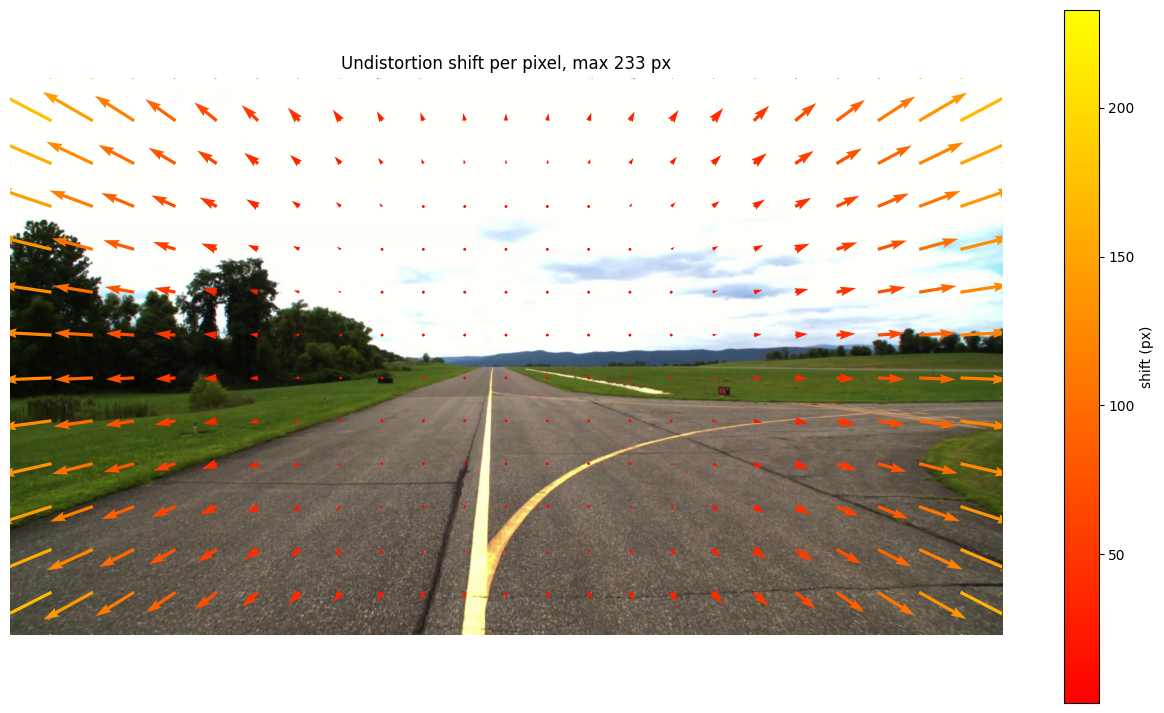

In [13]:
# Undistortion displacement field (April K, dist) on raw image - arrows at true pixel scale
im_ind = 4
raw = gnav.images_dict[im_ind]
H, W = raw.shape[:2]

# Grid of raw pixel locations
gu, gv = np.meshgrid(np.linspace(0, W-1, 25), np.linspace(0, H-1, 14))
px = np.stack((gu.ravel(), gv.ravel()), axis=1).reshape(-1,1,2)

# Undistorted pixel location (normalized coords back to pixels with the same K)
crit = (cv2.TERM_CRITERIA_COUNT | cv2.TERM_CRITERIA_EPS, 50, 1e-9)
und = cv2.undistortPoints(px, gnav.K, gnav.dist, P=gnav.K).reshape(-1,2)
d = und - px.reshape(-1,2)
mag = np.linalg.norm(d, axis=1)

plt.figure(figsize=(16, 9))
plt.imshow(cv2.cvtColor(raw, cv2.COLOR_BGR2RGB))
q = plt.quiver(px[:,0,0], px[:,0,1], d[:,0], d[:,1], mag, angles='xy', scale_units='xy', scale=1, cmap='autumn')
plt.colorbar(q, label='shift (px)')
plt.title(f'Undistortion shift per pixel, max {mag.max():.0f} px')
plt.axis('off'); plt.show()


[  75  850 2298  526] -> 1208748 pts per image


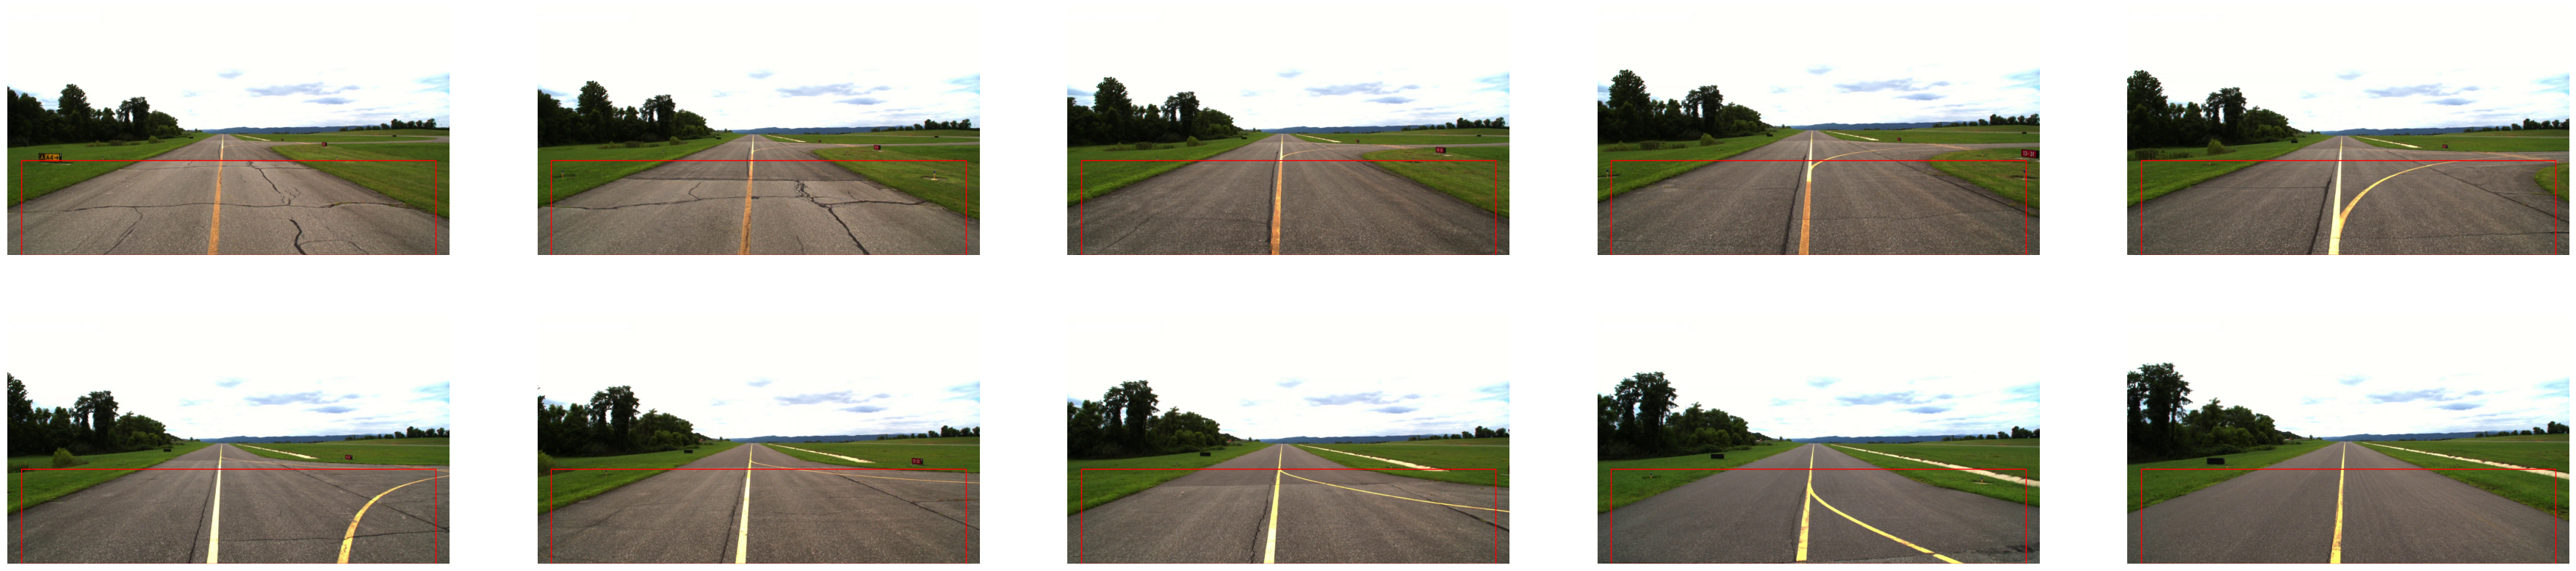

In [14]:
# Define ROI for image projection
# Per-image ROI (x, y, width, height) - lower image only, below horizon
# x0, y0 are a first guess (old 1600px ROI scaled by 2448/1600) - tune y0 by eye
x0, y0 = 75, 850 # CHANGED FROM 800
rois = np.array([(x0, y0, gnav.images_dict[i].shape[1] - 2*x0, gnav.images_dict[i].shape[0] - y0)
                 for i in range(gnav.im_num)])
print(rois[0], '->', rois[0, 2] * rois[0, 3], 'pts per image')

# Grab ROI pixels and draw boxes on all 10 frames
gnav.grab_image_pts_tot(rois)
gnav.plot_gnd_pts()


In [15]:
# ROI PROJECTION FUNCTION 

def project_roi(gnav, rois, d_pitch=0.0):
    """
    Grab ROI pixels and project onto the ground plane in the ref frame 
    Input: rois (num_ims x 4), each row (x, y, width, height)
           d_pitch: pitch perturbation (deg) about camera x-axis, applied to ALL images
                    + = optical axis tips up (COLMAP cam: y down, z forward)
    """
    gnav.grab_image_pts_tot(np.asarray(rois))

    # Pitch perturbation in camera frame (rotation about cam x, no translation)
    c, s = np.cos(np.deg2rad(d_pitch)), np.sin(np.deg2rad(d_pitch))
    T_pitch = np.array([[1, 0, 0, 0],
                        [0, c, -s, 0],
                        [0, s, c, 0],
                        [0, 0, 0, 1]])

    for i in range(gnav.im_num):
        # Unit vectors in camera coords
        pts_vec_c, pts_rgb_gnd = gnav.unit_vec_c(i)
        gnav.im_mosaic[i] = {'rgbc': pts_rgb_gnd}

        # Camera to world transform, with pitch perturbation
        homog_w2c, homog_c2w = gnav.get_pose_id(gnav.im_ids[i], i)
        homog_c2w = homog_c2w @ T_pitch

        # Transform to world coords and intersect with ground plane
        origin_c, pts_loc_w, pts_vec_w = gnav.unit_vec_tform(pts_vec_c, gnav.origin_w, homog_c2w)
        ranges, new_pts_w = gnav.pt_range(pts_vec_w, homog_c2w, origin_c, i)

        # Transfer points to reference frame
        __, new_pts_r, pts_vec_r = gnav.unit_vec_tform(new_pts_w, gnav.origin_w, gnav.tform_ref_frame_pts)

        # Store points and grayscale colors
        gnav.im_mosaic[i]['pts'] = new_pts_r
        gnav.im_mosaic[i]['color_g'] = gnav.conv_to_gray(gnav.im_mosaic[i]['rgbc'], i)

        # Image row of each point (same flattening order as pts) - for resolution check by row band
        gnav.im_mosaic[i]['rows'] = gnav.im_pts_2d[i]['pts'][..., 1].ravel()

        # Range check - r <= 0 means ray is at/above horizon
        r = gnav.im_pts_2d[i]['r']
        print(f"Image {i}: {r.size} pts, range min/max = {r.min():.3f}/{r.max():.3f}, "
              f"max/min = {r.max()/r.min():.1f}, r <= 0: {(r <= 0).sum()}")

# PROJECT ROIS

In [16]:
project_roi(gnav, rois)

Image 0: 1208748 pts, range min/max = 0.301/1.622, max/min = 5.4, r <= 0: 0
Image 1: 1208748 pts, range min/max = 0.302/1.671, max/min = 5.5, r <= 0: 0
Image 2: 1208748 pts, range min/max = 0.299/1.577, max/min = 5.3, r <= 0: 0
Image 3: 1208748 pts, range min/max = 0.291/1.405, max/min = 4.8, r <= 0: 0
Image 4: 1208748 pts, range min/max = 0.305/1.673, max/min = 5.5, r <= 0: 0
Image 5: 1208748 pts, range min/max = 0.304/1.654, max/min = 5.4, r <= 0: 0
Image 6: 1208748 pts, range min/max = 0.302/1.603, max/min = 5.3, r <= 0: 0
Image 7: 1208748 pts, range min/max = 0.305/1.667, max/min = 5.5, r <= 0: 0
Image 8: 1208748 pts, range min/max = 0.304/1.717, max/min = 5.6, r <= 0: 0
Image 9: 1208748 pts, range min/max = 0.294/1.416, max/min = 4.8, r <= 0: 0


In [17]:
# All 10 projected frames in ref frame - grayscale, every 4th pt for display speed
vis = o3d.visualization.Visualizer()
vis.create_window(window_name='Projected ROIs (April) - ref frame')
for i in range(gnav.im_num):
# for i in ([6]):
    cloud = o3d.geometry.PointCloud()
    cloud.points = o3d.utility.Vector3dVector(gnav.im_mosaic[i]['pts'][::4])
    cloud.colors = o3d.utility.Vector3dVector(gnav.im_mosaic[i]['color_g'][::4])
    vis.add_geometry(cloud)
# vis.add_geometry(o3d.geometry.TriangleMesh.create_coordinate_frame(size=1))
vis.run()
vis.destroy_window()


In [39]:
# Manual placement on satellite: ONE (scale, yaw, tx, ty) shared by all 10 frames
scale, yaw_deg, tx, ty = 89, 284, 187, 109   # tune by eye, re-run 
ind_params_april = np.tile([scale, np.deg2rad(yaw_deg), tx, ty], (gnav.im_num, 1))
gnav.implement_guess_ind(ind_params_april)

# Overlay: projected frames (orange tint) on satellite (gray)
vis = o3d.visualization.Visualizer()
vis.create_window(window_name=f'April placement: scale {scale}, yaw {yaw_deg} deg, t ({tx}, {ty})')

# Origin 
origin_axis = o3d.geometry.TriangleMesh.create_coordinate_frame(size=1)

sat_cloud = o3d.geometry.PointCloud()
sat_cloud.points = o3d.utility.Vector3dVector(gnav.ref_pts)
sat_cloud.colors = o3d.utility.Vector3dVector(gnav.ref_rgb)
vis.add_geometry(sat_cloud)

# for i in range(gnav.im_num):
for i in ([4]):
    
    # Camera frame: same chain as the pts (c2w -> ref frame -> xy scale -> guess tform); no d_pitch (c2w stored before T_pitch)
    p = ind_params_april[i]
    T_cam = gnav.tform_ref_frame_pts @ gnav.im_pts_2d[i]['c2w']
    T_cam[:2, 3] *= p[0]
    # Height above the map plane z_g scaled by p[0] (true rotation, no reflection)
    z_g = gnav.im_pts_best_guess[i]['pts'][:, 2].mean()
    T_cam[2, 3] = z_g + p[0] * (T_cam[2, 3] - z_g)
    T_cam = gnav.tform_create(p[2], p[3], 0, 0, 0, p[1]) @ T_cam
    # vis.add_geometry(o3d.geometry.TriangleMesh.create_coordinate_frame(size=20).transform(T_cam), reset_bounding_box=False)


    cloud = o3d.geometry.PointCloud()
    cloud.points = o3d.utility.Vector3dVector(gnav.im_pts_best_guess[i]['pts'][::4])
    cloud.colors = o3d.utility.Vector3dVector(gnav.im_mosaic[i]['color_g'][::4] * np.array([1.0, 0.55, 0.1]))
    vis.add_geometry(cloud, reset_bounding_box=False)



# vis.add_geometry(o3d.geometry.TriangleMesh.create_coordinate_frame(size=50))


# # # Zoom out the initial view (larger = farther; Open3D caps it at 2.0)
# ctr = vis.get_view_control()
# ctr.set_zoom(2.0)
# ctr.change_field_of_view(step=30)   # widen toward Open3D's 90° max (default 60°)
vis.run()
vis.destroy_window()

In [27]:
print(z_g, T_cam[2, 3])


1.0000868496525213 11.687036942099365


Image 0: SSD at (0,0) = 0.4611, min = 0.3665 at shift (+5, +2)
Image 1: SSD at (0,0) = 0.4541, min = 0.4141 at shift (+0, -1)
Image 2: SSD at (0,0) = 0.5407, min = 0.4448 at shift (+0, -1)
Image 3: SSD at (0,0) = 0.6332, min = 0.4667 at shift (-3, -3)
Image 4: SSD at (0,0) = 0.4811, min = 0.4334 at shift (+0, -1)
Image 5: SSD at (0,0) = 0.5175, min = 0.4963 at shift (-1, -1)
Image 6: SSD at (0,0) = 0.4587, min = 0.4587 at shift (+0, +0)
Image 7: SSD at (0,0) = 0.7521, min = 0.7081 at shift (-2, -1)
Image 8: SSD at (0,0) = 1.4995, min = 1.3271 at shift (+1, -5)
Image 9: SSD at (0,0) = 0.8573, min = 0.7821 at shift (+5, +4)


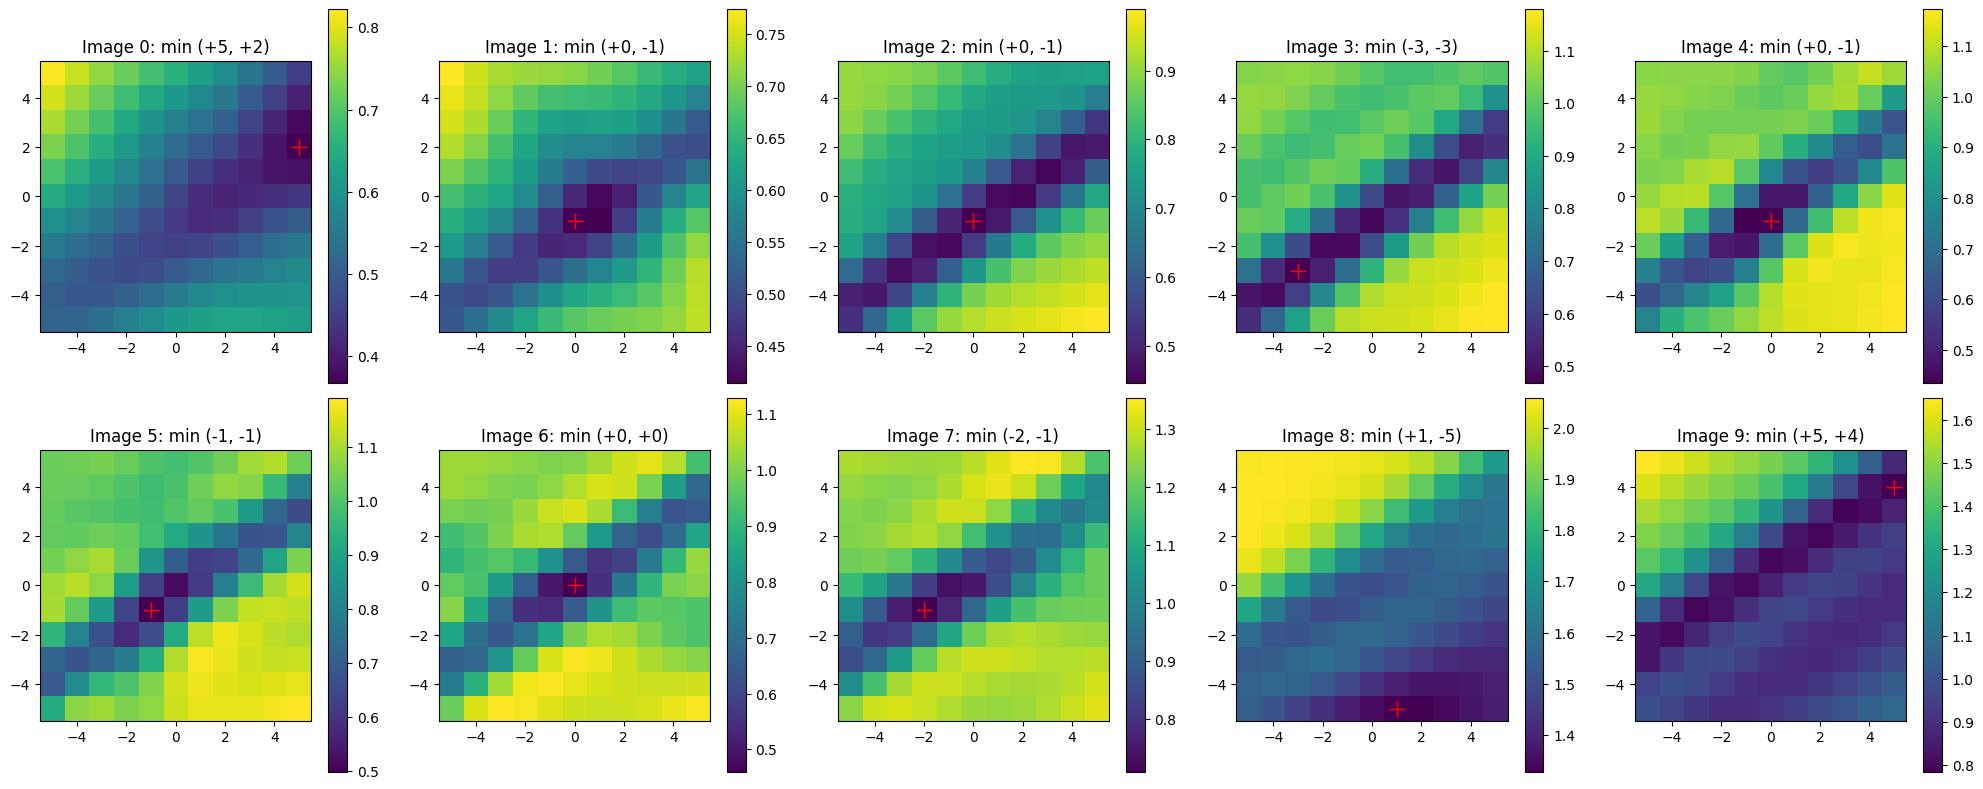

In [19]:
# Per-frame SSD around the shared April placement - offset of the minimum = error measure
n = 5
ssd_april = {}
fig, axs = plt.subplots(2, 5, figsize=(20, 8))
for i, ax in zip(range(gnav.im_num), axs.ravel()):
    ssds = ssd_april[i] = gnav.ssd_norm(i, n)
    ix, iy = np.unravel_index(np.argmin(ssds), ssds.shape)
    print(f"Image {i}: SSD at (0,0) = {ssds[n, n]:.4f}, min = {ssds.min():.4f} at shift ({ix-n:+d}, {iy-n:+d})")
    im = ax.imshow(ssds.T, origin='lower', extent=[-n-0.5, n+0.5, -n-0.5, n+0.5])
    ax.plot(ix-n, iy-n, 'r+', ms=12)
    ax.set_title(f'Image {i}: min ({ix-n:+d}, {iy-n:+d})')
    fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

In [21]:
import plotly.graph_objects as go

# SSD surface plot (plotly) - image 4, from the per-frame SSD above (same style as calibration_test)
im_ind = 4
ssds = ssd_april[im_ind]   # dict name copied from calib_raw - holds VT-fixed SSDs here
x = np.linspace(-n, n, 2*n + 1)
Y, X = np.meshgrid(x, x)  # ssds indexed [shiftx + n, shifty + n]

idrow, idcol = np.unravel_index(np.argmin(ssds), ssds.shape)
fig = go.Figure()
fig.add_surface(x=X, y=Y, z=ssds, colorscale='Viridis', colorbar=dict(title='SSD'), name='SSD Surface')
fig.add_trace(go.Scatter3d(x=[idrow - n], y=[idcol - n], z=[ssds[idrow, idcol]],
                           mode='markers', marker=dict(size=6, color='red'), name='Min SSD'))
fig.add_trace(go.Scatter3d(x=[0], y=[0], z=[ssds[n, n]],
                           mode='markers', marker=dict(size=6, color='black'), name='Placement (0,0)'))
fig.update_layout(
    title=f'Normalized SSD: image {im_ind} (VT-fixed)',
    scene=dict(xaxis=dict(title='X Shift (pixels)', range=[-n, n], dtick=1),
               yaxis=dict(title='Y Shift (pixels)', range=[-n, n], dtick=1),
               zaxis=dict(title='SSD'),
               camera=dict(eye=dict(x=1.5, y=1.5, z=1.2)),
               aspectmode='cube'),
    width=900, height=800)
fig.show()

# GRADIENTS

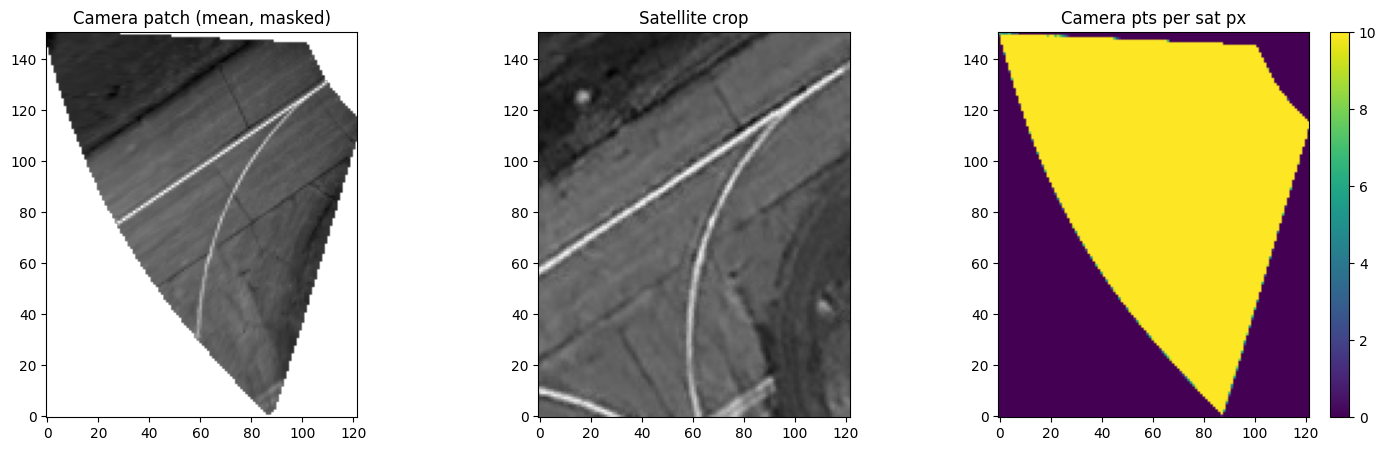

In [22]:
# Rasterized patch vs satellite crop + camera pts per sat px (image 4)
patch, sat, cnt = gnav.raster_patch(4)
fig, axs = plt.subplots(1, 3, figsize=(18, 5))
axs[0].imshow(patch, cmap='gray', origin='lower'); axs[0].set_title('Camera patch (mean, masked)')
axs[1].imshow(sat, cmap='gray', origin='lower'); axs[1].set_title('Satellite crop')
im = axs[2].imshow(cnt, cmap='viridis', origin='lower', vmax=10); axs[2].set_title('Camera pts per sat px')
fig.colorbar(im, ax=axs[2])
plt.show()


Image 4: S = 0.795


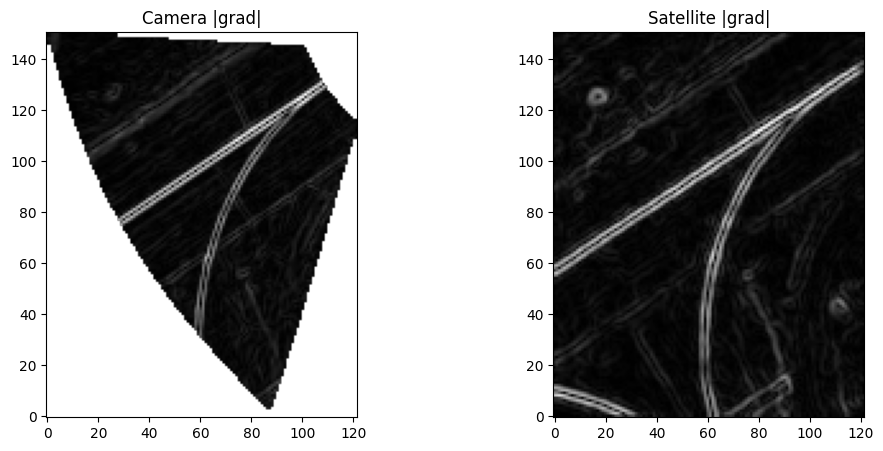

In [23]:
# Gradient-orientation score, no shift (image 4)
S, m_im, m_sat = gnav.grad_score(patch, sat)
print(f"Image 4: S = {S:.3f}")
fig, axs = plt.subplots(1, 2, figsize=(12, 5))
axs[0].imshow(m_im, cmap='gray', origin='lower'); axs[0].set_title('Camera |grad|')
axs[1].imshow(m_sat, cmap='gray', origin='lower'); axs[1].set_title('Satellite |grad|')
plt.show()


Image 0: S at (0,0) = 0.498, max = 0.588 at shift (-1, +1)
Image 1: S at (0,0) = 0.535, max = 0.628 at shift (-1, +1)
Image 2: S at (0,0) = 0.662, max = 0.753 at shift (+1, +2)
Image 3: S at (0,0) = 0.704, max = 0.790 at shift (+0, +1)
Image 4: S at (0,0) = 0.795, max = 0.812 at shift (+0, +1)
Image 5: S at (0,0) = 0.796, max = 0.813 at shift (+1, +1)
Image 6: S at (0,0) = 0.826, max = 0.826 at shift (+0, +0)
Image 7: S at (0,0) = 0.780, max = 0.793 at shift (+2, +1)
Image 8: S at (0,0) = 0.609, max = 0.664 at shift (+3, +1)
Image 9: S at (0,0) = 0.621, max = 0.650 at shift (+3, +1)


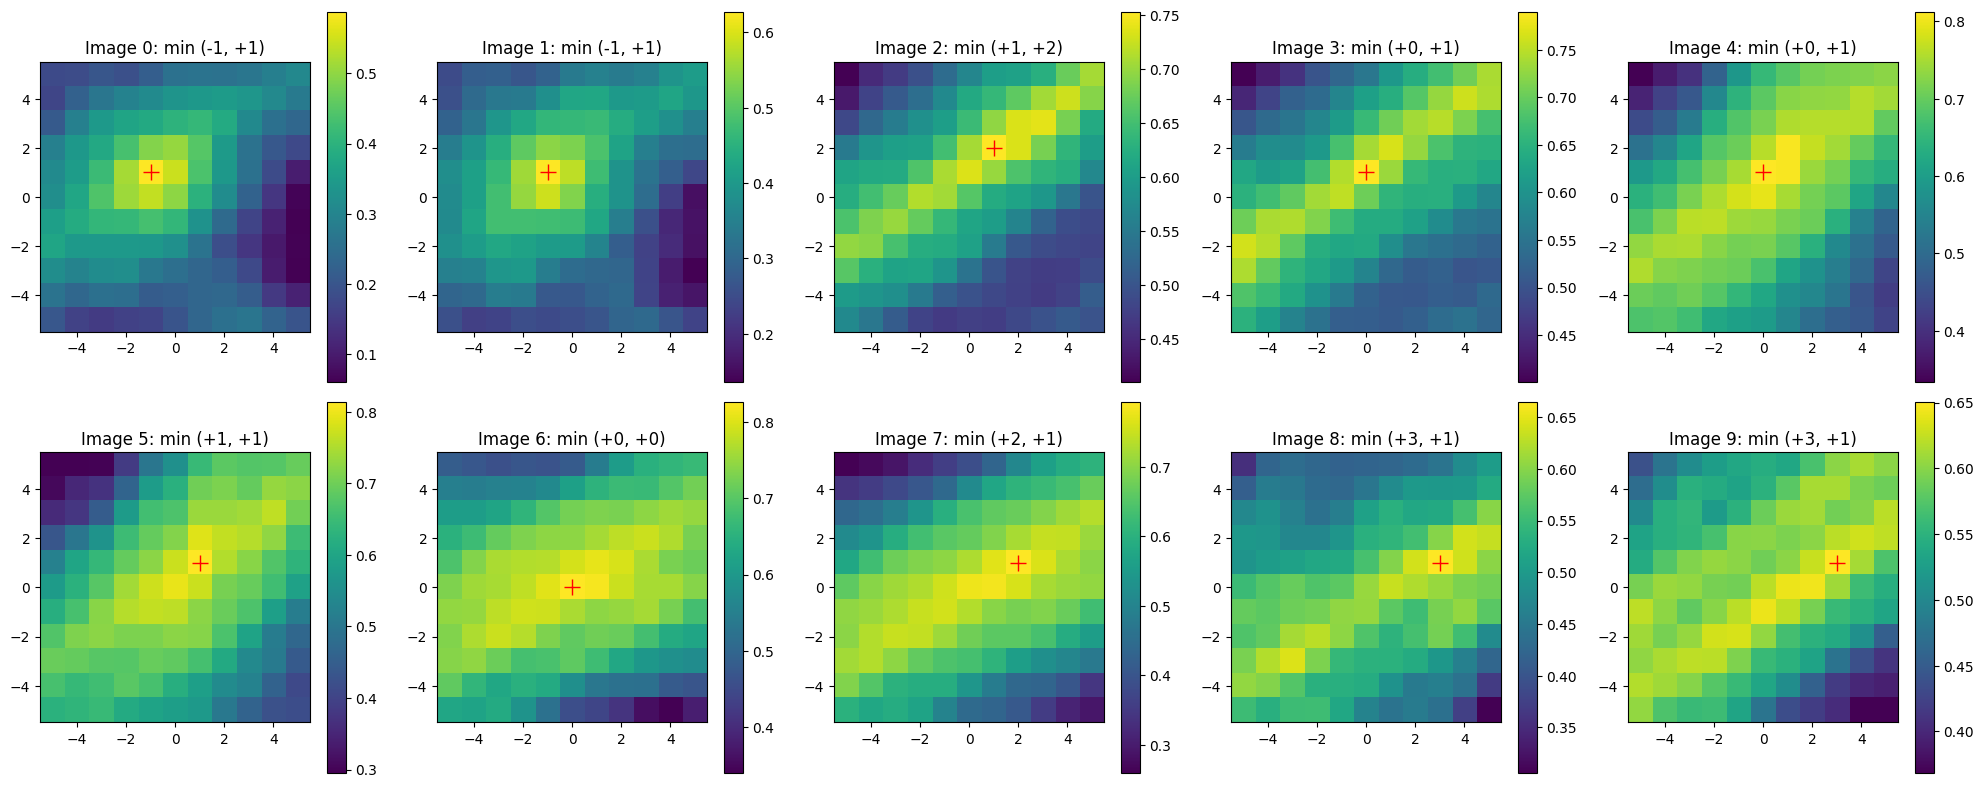

In [24]:
# Per-frame gradient score around the shared VT placement - offset of the max = error measure
n = 5
gs_vt = {}
fig, axs = plt.subplots(2, 5, figsize=(20, 8))
for i, ax in zip(range(gnav.im_num), axs.ravel()):
    S = gs_vt[i] = gnav.grad_score_shifts(i, n)
    ix, iy = np.unravel_index(np.argmax(S), S.shape)
    # ix, iy = np.unravel_index(np.argmin(S), S.shape)
    print(f"Image {i}: S at (0,0) = {S[n, n]:.3f}, max = {S.max():.3f} at shift ({ix-n:+d}, {iy-n:+d})")
    # print(f"Image {i}: S at (0,0) = {S[n, n]:.3f}, min = {S.min():.3f} at shift ({ix-n:+d}, {iy-n:+d})")
    im = ax.imshow(S.T, origin='lower', extent=[-n-0.5, n+0.5, -n-0.5, n+0.5])
    ax.plot(ix-n, iy-n, 'r+', ms=12)
    ax.set_title(f'Image {i}: min ({ix-n:+d}, {iy-n:+d})')
    fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()


In [44]:
# SSD surface plot (plotly) - image 4, from the per-frame SSD above (same style as calibration_test)
im_ind = 1
ssds_grad = gs_vt[im_ind]   # dict name copied from calib_raw - holds VT-fixed SSDs here
x = np.linspace(-n, n, 2*n + 1)
Y, X = np.meshgrid(x, x)  # ssds indexed [shiftx + n, shifty + n]

# idrow, idcol = np.unravel_index(np.argmin(ssds_grad), ssds_grad.shape)
idrow, idcol = np.unravel_index(np.argmax(ssds_grad), ssds_grad.shape)
fig = go.Figure()
fig.add_surface(x=X, y=Y, z=ssds_grad, colorscale='Viridis', colorbar=dict(title='SSD'), name='SSD Surface')
# Watershed plane at the (0,0) score - semi-transparent, single color
fig.add_surface(x=X, y=Y, z=np.full_like(ssds_grad, ssds_grad[n, n]), colorscale=[[0, 'red'], [1, 'red']],
                opacity=0.4, showscale=False, name='Watershed (0,0)')
fig.add_trace(go.Scatter3d(x=[idrow - n], y=[idcol - n], z=[ssds_grad[idrow, idcol]],
                           mode='markers', marker=dict(size=6, color='red'), name='Prediction'))
fig.add_trace(go.Scatter3d(x=[0], y=[0], z=[ssds_grad[n, n]],
                           mode='markers', marker=dict(size=6, color='black'), name='State Estimate'))
fig.update_layout(
    title=f'GRADIENT SCORE: image {im_ind} (VT-fixed)',
    scene=dict(xaxis=dict(title='X Shift (pixels)', range=[-n, n], dtick=1),
               yaxis=dict(title='Y Shift (pixels)', range=[-n, n], dtick=1),
               zaxis=dict(title='SSD'),
               camera=dict(eye=dict(x=1.5, y=1.5, z=1.2)),
               aspectmode='cube'),
    legend=dict(x=0.02, y=0.98),   # top-left, clear of the colorbar
    width=900, height=800)
fig.show()

In [26]:
# Gradient overlay (Open3D): camera |grad| (orange) on satellite |grad| (gray), rasterized grid, image 4, no shift
patch, sat, __ = gnav.raster_patch(4)
S, m_im, m_sat = gnav.grad_score(patch, sat)

# Grid coords (col, row) of every px - both images share the grid, camera lifted slightly so it draws on top
rr, cc = np.mgrid[0:sat.shape[0], 0:sat.shape[1]]
xy = np.stack([cc.ravel(), rr.ravel()], axis=1).astype(np.float64)

# Display scaling: each |grad| / its own 99th percentile, clipped to 1
g_sat = np.minimum(m_sat / np.nanpercentile(m_sat, 99), 1).ravel()
g_im = np.minimum(m_im / np.nanpercentile(m_im, 99), 1).ravel()
ok = np.isfinite(g_im)   # camera px inside footprint only

sat_cloud = o3d.geometry.PointCloud()
sat_cloud.points = o3d.utility.Vector3dVector(np.column_stack([xy, np.zeros(len(xy))]))
sat_cloud.colors = o3d.utility.Vector3dVector(np.repeat(g_sat[:, None], 3, axis=1))

im_cloud = o3d.geometry.PointCloud()
im_cloud.points = o3d.utility.Vector3dVector(np.column_stack([xy[ok], np.full(ok.sum(), 0.1)]) + np.array([0,0,-1]))
im_cloud.colors = o3d.utility.Vector3dVector(g_im[ok, None] * np.array([1.0, 0.55, 0.1]))

vis = o3d.visualization.Visualizer()
vis.create_window(window_name=f'Gradient overlay, image 4, S = {S:.1f}')
vis.add_geometry(sat_cloud)
vis.add_geometry(im_cloud)
vis.run()
vis.destroy_window()


# PHASE Correlation

In [ ]:
# Per-frame phase correlation around the shared VT placement - offset of the max = error measure
n = 5
pc_vt = {}
fig, axs = plt.subplots(2, 5, figsize=(20, 8))
for i, ax in zip(range(gnav.im_num), axs.ravel()):
    P = pc_vt[i] = gnav.phase_corr(i, n)
    ix, iy = np.unravel_index(np.argmax(P), P.shape)
    print(f"Image {i}: P at (0,0) = {P[n, n]:.4f}, max = {P.max():.4f} at shift ({ix-n:+d}, {iy-n:+d})")
    im = ax.imshow(P.T, origin='lower', extent=[-n-0.5, n+0.5, -n-0.5, n+0.5])
    ax.plot(ix-n, iy-n, 'r+', ms=12)
    ax.set_title(f'Image {i}: max ({ix-n:+d}, {iy-n:+d})')
    fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()